# TA-EVRP Sweep Analysis

Visualises `results/ta_evrp_results.csv` produced by `sweep_ta_evrp.py`.

**Current sweep:** 3 planners × 5 TRSP agents × 3 networks × 3 K values = 135 runs

In [19]:
from pathlib import Path
import warnings
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'figure.dpi': 120,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'font.size': 11,
})

CSV_PATH = Path('../results/ta_evrp_results.csv')

# ── Load ─────────────────────────────────────────────────────────────────────
raw = pd.read_csv(CSV_PATH)
raw = raw[raw['status'] == 'ok'].copy()

# ── Derived columns ───────────────────────────────────────────────────────────
_NET_LABELS = {
    'grid_road':            'Grid',
    'rand_grid_road_final': 'RandGrid',
    'ames_campus_final':    'Ames',
}
raw['network']  = raw['network_net_path'].apply(lambda p: _NET_LABELS.get(Path(p).stem, Path(p).stem))
raw['planner']  = raw['evrp_planner'].map({'milp': 'MILP', 'heuristic': 'Heuristic', 'mtsp': 'mTSP'})
raw['agent']    = raw['trsp_agent']
raw['K']        = raw['traffic_psl_K'].astype(int)
raw['throughput_tasks_per_h'] = raw['customers_served'] / raw['makespan_h'].replace(0, np.nan)

# Average across any duplicate (planner, agent, network, K) combos
GROUP = ['planner', 'agent', 'network', 'K']
METRICS = ['makespan_s', 'total_distance_km', 'total_recharges',
           'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']
df = raw.groupby(GROUP)[METRICS].mean().reset_index()

# ── Style constants ───────────────────────────────────────────────────────────
PLANNER_ORDER  = [p for p in ['MILP', 'Heuristic', 'mTSP'] if p in df['planner'].unique()]
AGENT_ORDER    = [a for a in ['dijkstra', 'sarsa', 'dqn', 'a2c', 'ppo'] if a in df['agent'].unique()]
NET_ORDER      = sorted(df['network'].unique())
K_VALUES       = sorted(df['K'].unique())

AGENT_LABELS   = {'dijkstra': 'Dijkstra', 'sarsa': 'SARSA', 'dqn': 'DQN', 'a2c': 'A2C', 'ppo': 'PPO'}
PLANNER_COLORS = {'MILP': '#4C72B0', 'Heuristic': '#DD8452', 'mTSP': '#55A868'}

_agent_palette = plt.cm.tab10(np.linspace(0, 0.9, len(AGENT_ORDER)))
AGENT_COLORS   = {a: _agent_palette[i] for i, a in enumerate(AGENT_ORDER)}

K_HATCHES = {1: '', 3: '///', 4: 'xxx'}
NET_LINESTYLES = {n: ls for n, ls in zip(NET_ORDER, ['-', '--', ':'])}
NET_MARKERS    = {n: m  for n, m  in zip(NET_ORDER, ['o', 's', '^'])}

print(f"Rows (after dedup): {len(df)}")
print(f"Planners  : {PLANNER_ORDER}")
print(f"Agents    : {AGENT_ORDER}")
print(f"Networks  : {NET_ORDER}")
print(f"K values  : {K_VALUES}")
df.head()

Rows (after dedup): 180
Planners  : ['MILP', 'Heuristic', 'mTSP']
Agents    : ['dijkstra', 'sarsa', 'dqn', 'a2c', 'ppo']
Networks  : ['Ames', 'Grid', 'RandGrid']
K values  : [1, 2, 3, 4]


,planner,agent,network,K,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h,avg_inter_customer_gap_s
0,Heuristic,a2c,Ames,1,460.0,11.94596,0.0,10.0,78.260870,40.555556
1,Heuristic,a2c,Ames,2,539.0,11.94596,0.0,10.0,66.790353,46.333333
2,Heuristic,a2c,Ames,3,538.0,11.94596,0.0,10.0,66.914498,40.333333
3,Heuristic,a2c,Ames,4,439.0,11.94596,0.0,10.0,82.004556,34.111111
4,Heuristic,a2c,Grid,1,800.0,21.69120,0.0,10.0,45.000000,61.666667


## Summary statistics

Mean metrics grouped by planner and agent (averaged over networks and K).

In [20]:
summary = (
    df.groupby(['planner', 'agent'])
    [['makespan_s', 'total_distance_km', 'total_recharges',
      'customers_served', 'throughput_tasks_per_h']]
    .mean()
    .round(2)
)
summary

makespan_s  total_distance_km  total_recharges  \
planner   agent                                                      
Heuristic a2c           434.33              12.42             0.08   
          dijkstra      445.75              12.56             0.00   
          dqn           442.50              12.29             0.00   
          ppo           448.50              12.42             0.00   
          sarsa         425.50              12.58             0.00   
MILP      a2c           709.33              10.40             1.50   
          dijkstra      697.08              10.40             1.50   
          dqn           635.67              10.22             1.25   
          ppo           685.17              10.22             1.25   
          sarsa         668.25              10.22             1.25   
mTSP      a2c           369.75              14.09             0.00   
          dijkstra      384.08              14.09             0.00   
          dqn           356.17              13.99             0.00   
          ppo           374.25              14.03             0.00   
          sarsa         383.58              13.99             0.00   

                    customers_served  throughput_tasks_per_h  
planner   agent                                               
Heuristic a2c                   9.67                  116.24  
          dijkstra              9.67                  117.03  
          dqn                   9.17                  107.12  
          ppo                   9.67                  113.05  
          sarsa                 9.67                  114.18  
MILP      a2c                   9.50                   67.43  
          dijkstra              9.50                   70.80  
          dqn                   8.92                   66.37  
          ppo                   8.92                   61.77  
          sarsa                 8.92                   58.72  
mTSP      a2c                  10.00                  140.67  
          dijkstra             10.00                  139.68  
          dqn                   9.75                  137.99  
          ppo                   9.83                  136.61  
          sarsa                 9.75                  116.42

## TRSP agent comparison

Mean metrics for each TRSP agent, grouped by network. Bars show agents; columns show the four key metrics.
Averaged over all planners and K values.

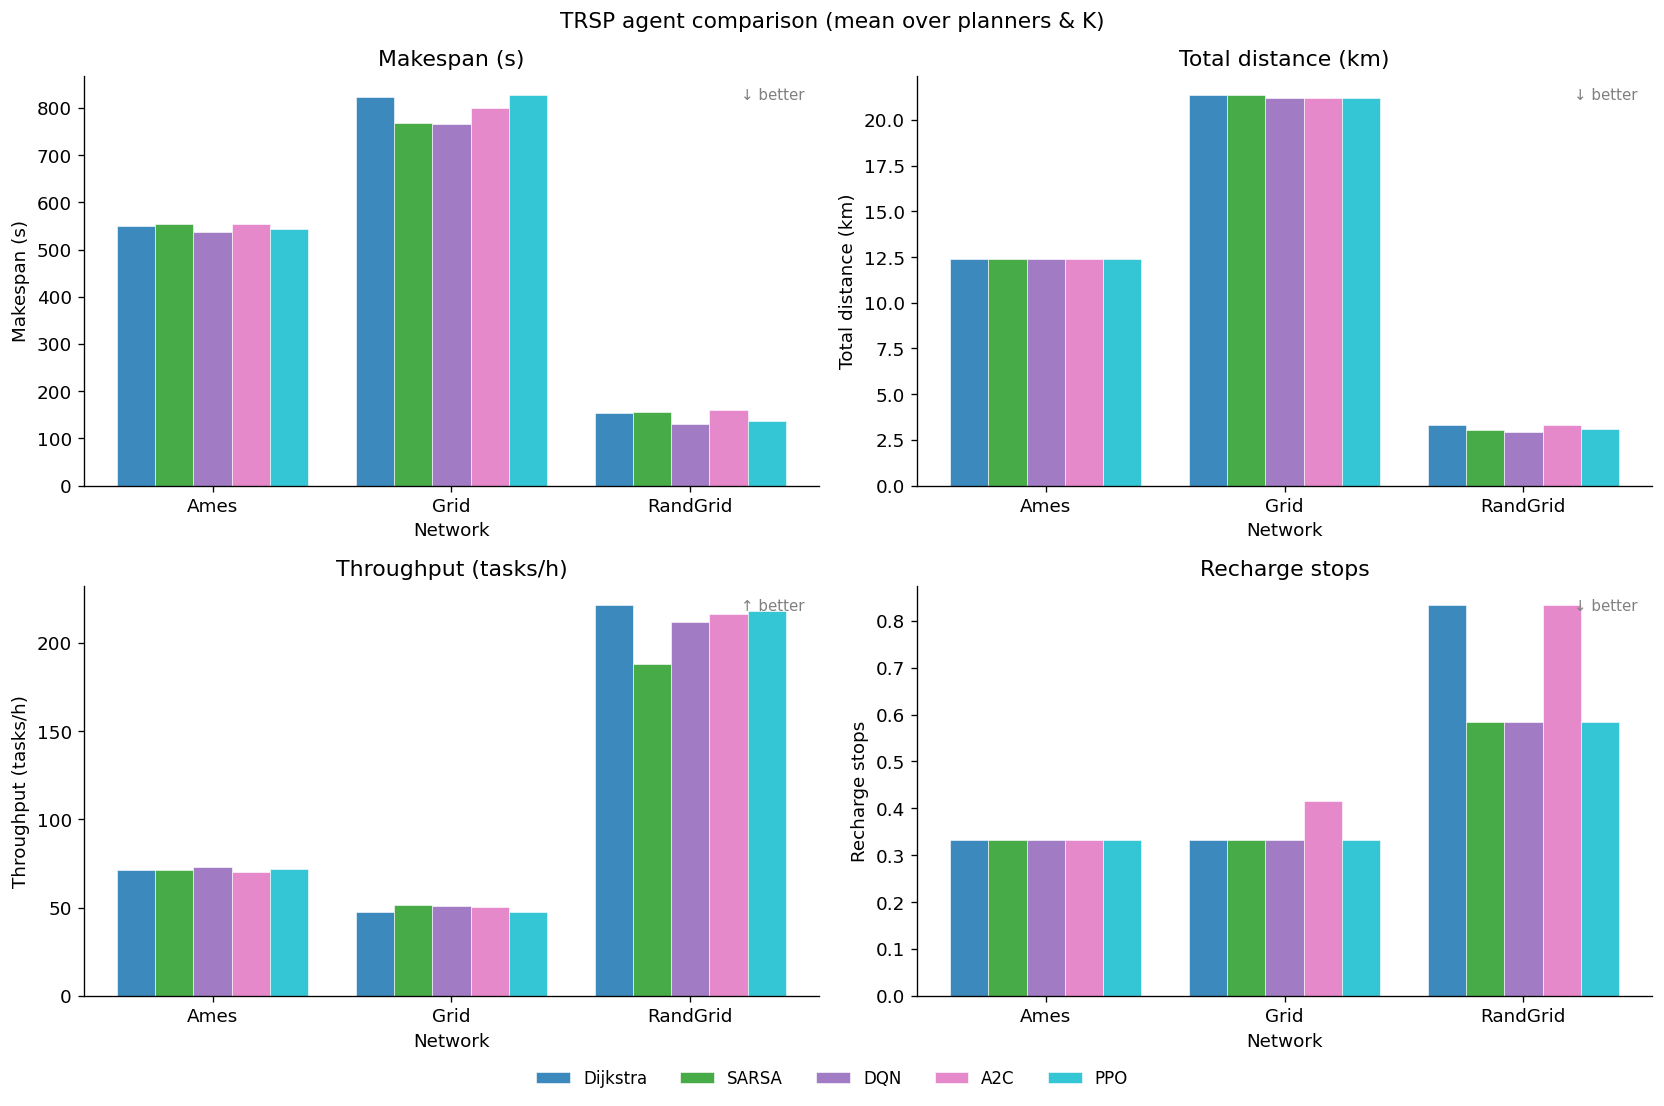

In [21]:
metrics_cfg = [
    ('makespan_s',             'Makespan (s)',         False),
    ('total_distance_km',      'Total distance (km)',  False),
    ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
    ('total_recharges',        'Recharge stops',       False),
]

agg_agent = df.groupby(['agent', 'network'])[METRICS].mean().reset_index()

x       = np.arange(len(NET_ORDER))
width   = 0.8 / len(AGENT_ORDER)
offsets = np.linspace(-(len(AGENT_ORDER)-1)/2*width, (len(AGENT_ORDER)-1)/2*width, len(AGENT_ORDER))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('TRSP agent comparison (mean over planners & K)', fontsize=13)

for ax, (metric, ylabel, higher_better) in zip(axes.flat, metrics_cfg):
    for offset, agent in zip(offsets, AGENT_ORDER):
        vals = []
        for net in NET_ORDER:
            sub = agg_agent[(agg_agent['agent'] == agent) & (agg_agent['network'] == net)]
            vals.append(sub[metric].mean() if len(sub) else np.nan)
        ax.bar(
            x + offset, vals, width,
            color=AGENT_COLORS[agent],
            alpha=0.87,
            label=AGENT_LABELS[agent],
            edgecolor='white', linewidth=0.4,
        )
    ax.set_xticks(x)
    ax.set_xticklabels(NET_ORDER)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(AGENT_ORDER),
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

## RL agent improvement over Dijkstra baseline

Percent change in makespan and throughput when switching from Dijkstra to each RL agent,
broken out by planner and network. Positive makespan delta = RL is slower (bad).

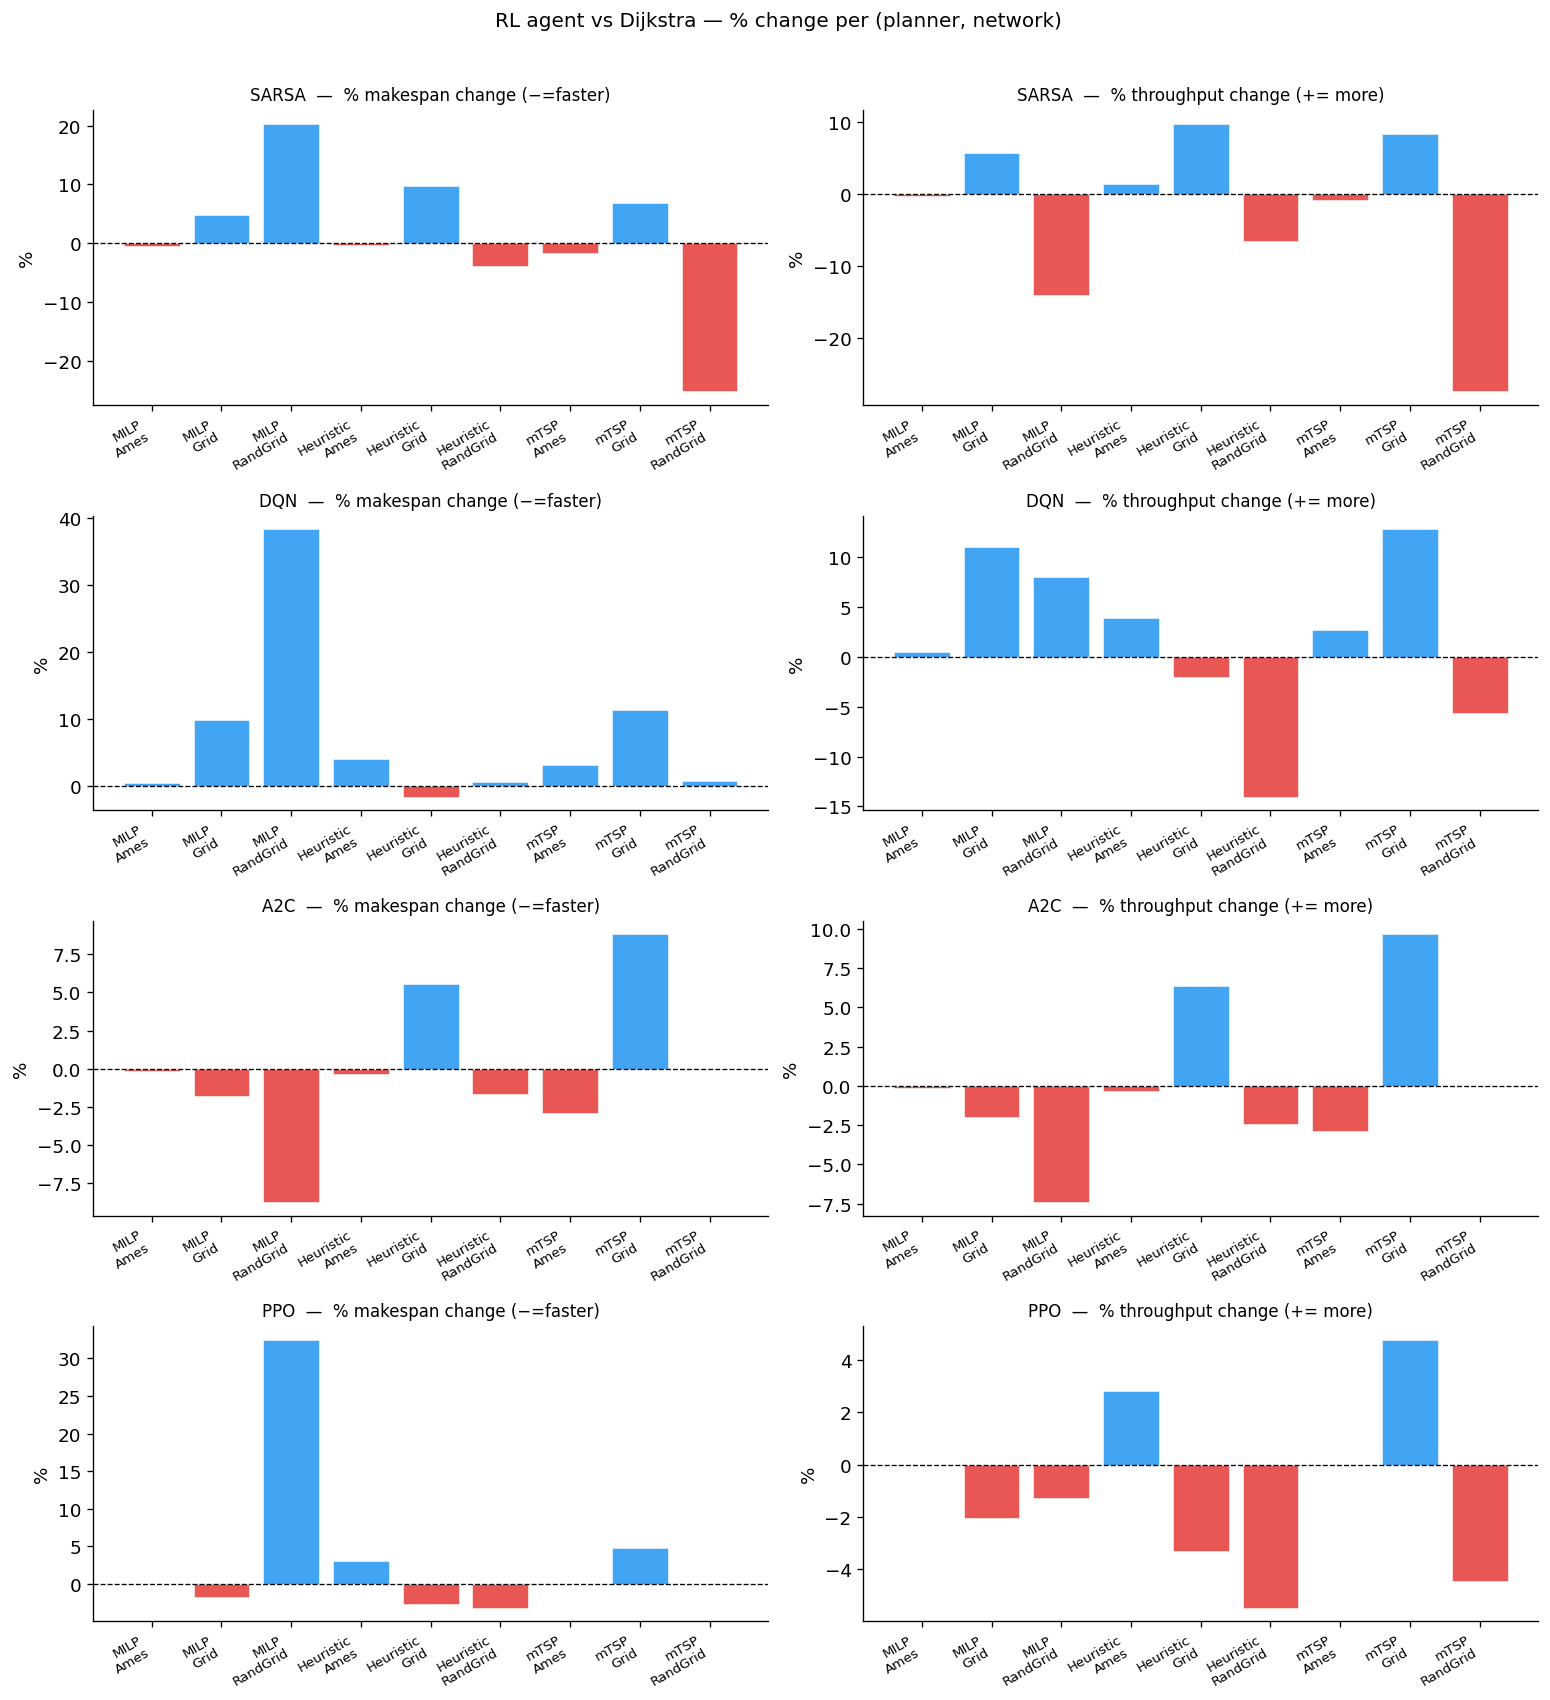

In [22]:
RL_AGENTS = [a for a in AGENT_ORDER if a != 'dijkstra']

# Build planner×network mean for each agent
pn_agent = df.groupby(['planner', 'agent', 'network'])[METRICS].mean().reset_index()

fig, axes = plt.subplots(len(RL_AGENTS), 2, figsize=(13, 3.5 * len(RL_AGENTS)), squeeze=False)
fig.suptitle('RL agent vs Dijkstra — % change per (planner, network)', fontsize=12, y=1.01)

for row_i, rl_agent in enumerate(RL_AGENTS):
    for col_i, (metric, label, sign) in enumerate([
        ('makespan_s',             '% makespan change (−=faster)', -1),
        ('throughput_tasks_per_h', '% throughput change (+= more)', +1),
    ]):
        ax = axes[row_i][col_i]
        combo_labels, values = [], []
        for pl in PLANNER_ORDER:
            for net in NET_ORDER:
                base = pn_agent[(pn_agent['planner'] == pl) &
                                (pn_agent['agent'] == 'dijkstra') &
                                (pn_agent['network'] == net)][metric].values
                rl   = pn_agent[(pn_agent['planner'] == pl) &
                                (pn_agent['agent'] == rl_agent) &
                                (pn_agent['network'] == net)][metric].values
                if len(base) and len(rl) and base[0] != 0:
                    pct = sign * (rl[0] - base[0]) / abs(base[0]) * 100
                    combo_labels.append(f'{pl}\n{net}')
                    values.append(pct)
        colors = ['#2196F3' if v >= 0 else '#E53935' for v in values]
        ax.bar(range(len(values)), values, color=colors, alpha=0.85, edgecolor='white', linewidth=0.4)
        ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
        ax.set_xticks(range(len(combo_labels)))
        ax.set_xticklabels(combo_labels, fontsize=8, rotation=30, ha='right')
        ax.set_ylabel('%')
        ax.set_title(f'{AGENT_LABELS[rl_agent]}  —  {label}', fontsize=10)

fig.tight_layout()
plt.show()

## Planner comparison by network

Mean metrics per planner, grouped by network. Averaged over agents and K values.

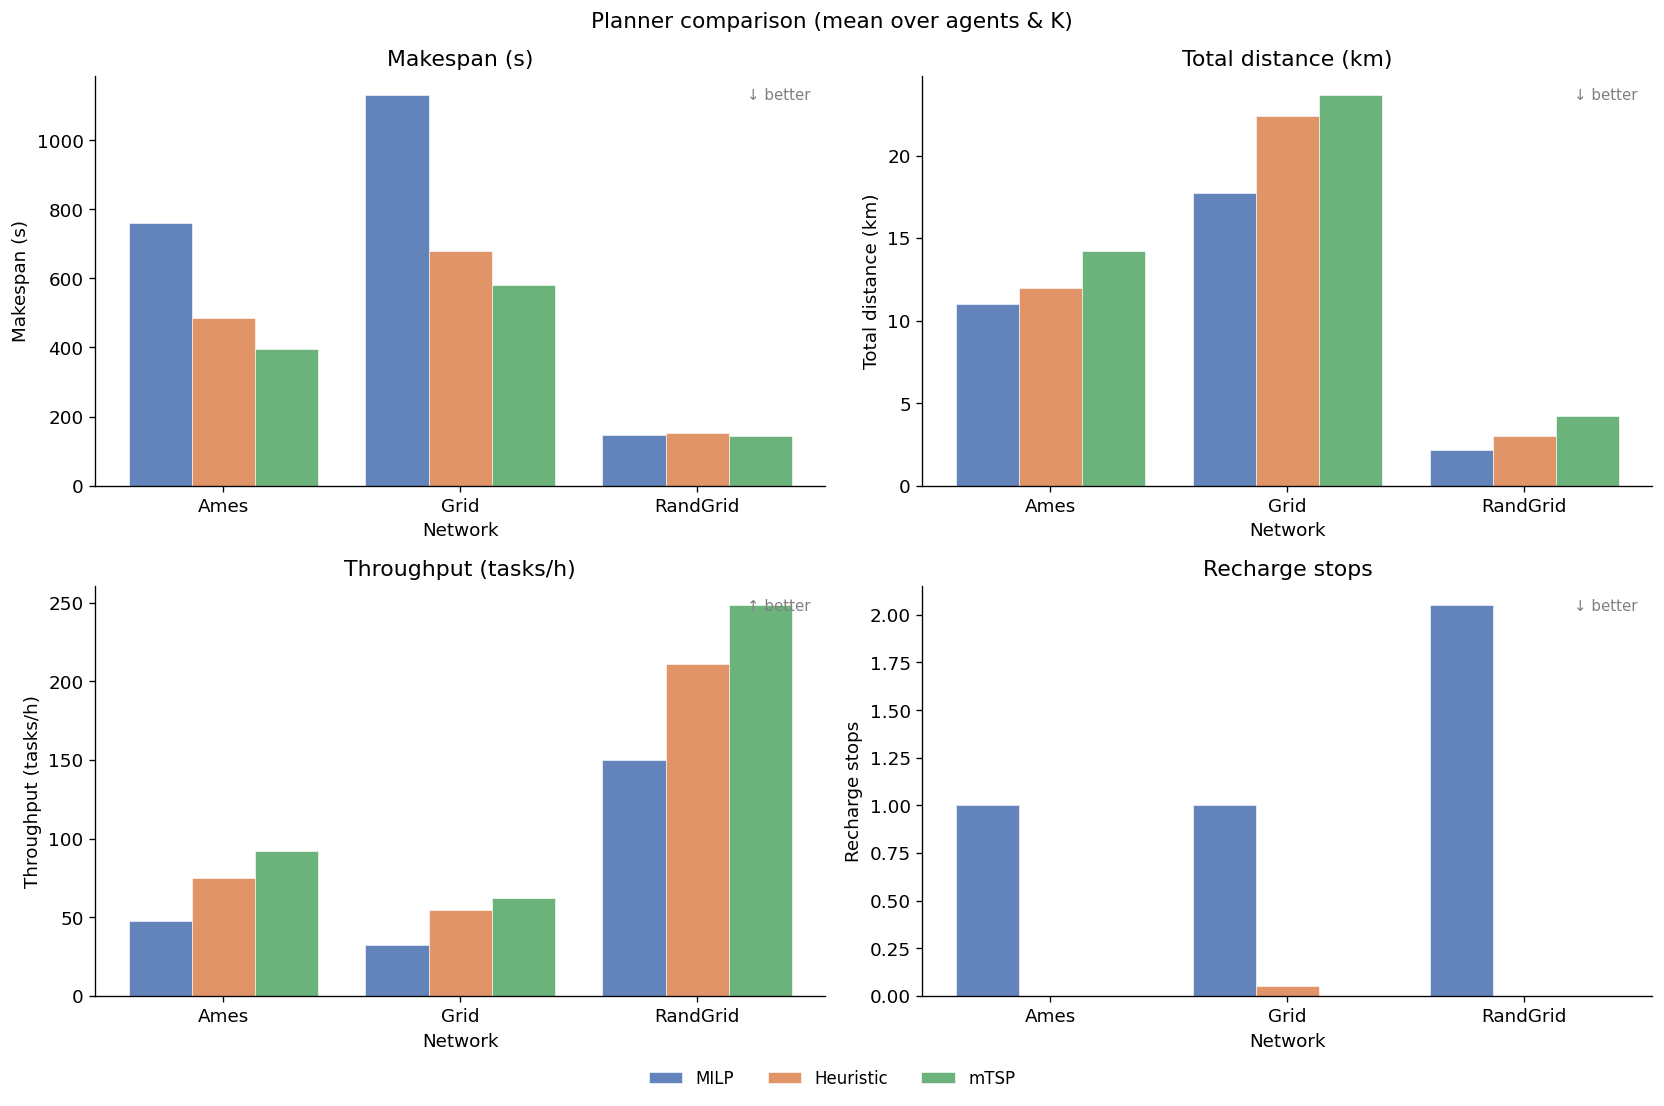

In [23]:
agg_planner = df.groupby(['planner', 'network'])[METRICS].mean().reset_index()

x2       = np.arange(len(NET_ORDER))
width2   = 0.8 / len(PLANNER_ORDER)
offsets2 = np.linspace(-(len(PLANNER_ORDER)-1)/2*width2, (len(PLANNER_ORDER)-1)/2*width2, len(PLANNER_ORDER))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
fig.suptitle('Planner comparison (mean over agents & K)', fontsize=13)

for ax, (metric, ylabel, higher_better) in zip(axes.flat, metrics_cfg):
    for offset, planner in zip(offsets2, PLANNER_ORDER):
        vals = [
            agg_planner[(agg_planner['planner'] == planner) &
                        (agg_planner['network'] == net)][metric].mean()
            for net in NET_ORDER
        ]
        ax.bar(
            x2 + offset, vals, width2,
            color=PLANNER_COLORS[planner],
            alpha=0.87, label=planner,
            edgecolor='white', linewidth=0.4,
        )
    ax.set_xticks(x2)
    ax.set_xticklabels(NET_ORDER)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(PLANNER_ORDER),
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=10)
fig.tight_layout()
plt.show()

## Effect of traffic time-slots K

One line per (planner, network); x-axis = K. Averaged over agents.

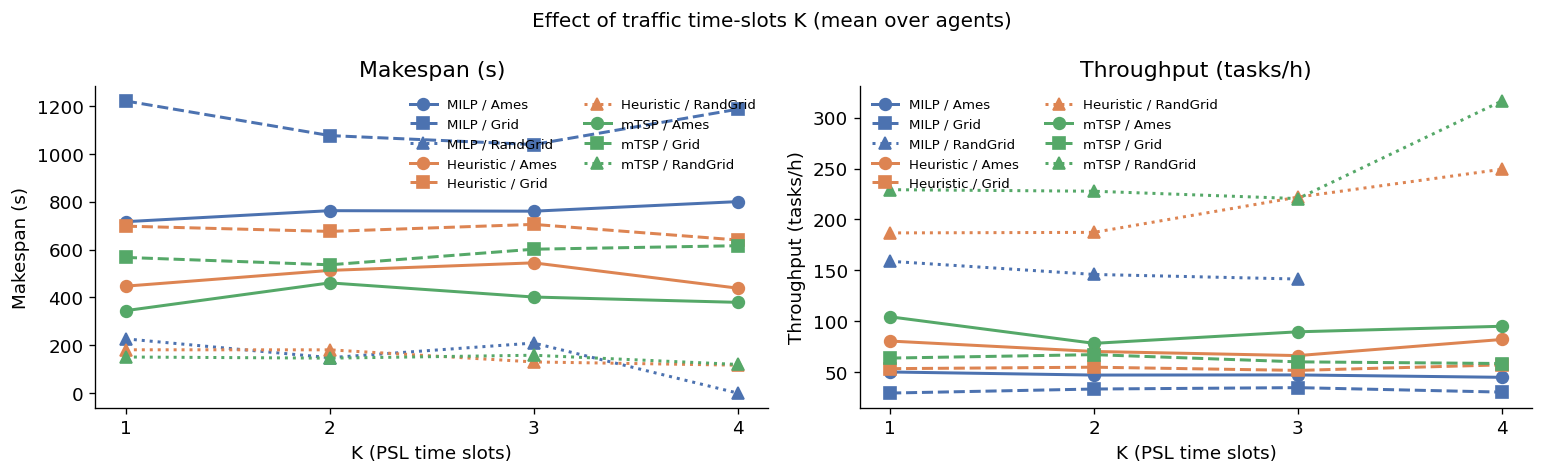

In [24]:
if len(K_VALUES) < 2:
    print("Only one K value — add more to sweep.yaml to see this plot.")
else:
    agg_k = df.groupby(['planner', 'network', 'K'])[METRICS].mean().reset_index()

    k_metrics = [('makespan_s', 'Makespan (s)'), ('throughput_tasks_per_h', 'Throughput (tasks/h)')]
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle('Effect of traffic time-slots K (mean over agents)', fontsize=12)

    for ax, (metric, ylabel) in zip(axes, k_metrics):
        for planner in PLANNER_ORDER:
            for net in NET_ORDER:
                sub = agg_k[(agg_k['planner'] == planner) & (agg_k['network'] == net)].sort_values('K')
                if sub.empty:
                    continue
                ax.plot(
                    sub['K'], sub[metric],
                    color=PLANNER_COLORS.get(planner, '#888'),
                    linestyle=NET_LINESTYLES.get(net, '-'),
                    marker=NET_MARKERS.get(net, 'o'),
                    label=f'{planner} / {net}',
                    markersize=7, linewidth=1.8,
                )
        ax.set_xlabel('K (PSL time slots)')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.set_xticks(K_VALUES)
        ax.legend(frameon=False, fontsize=8, ncol=2)

    fig.tight_layout()
    plt.show()

## Heatmap: makespan by planner × agent

One heatmap per network. Cell value = mean makespan (s) over all K values.

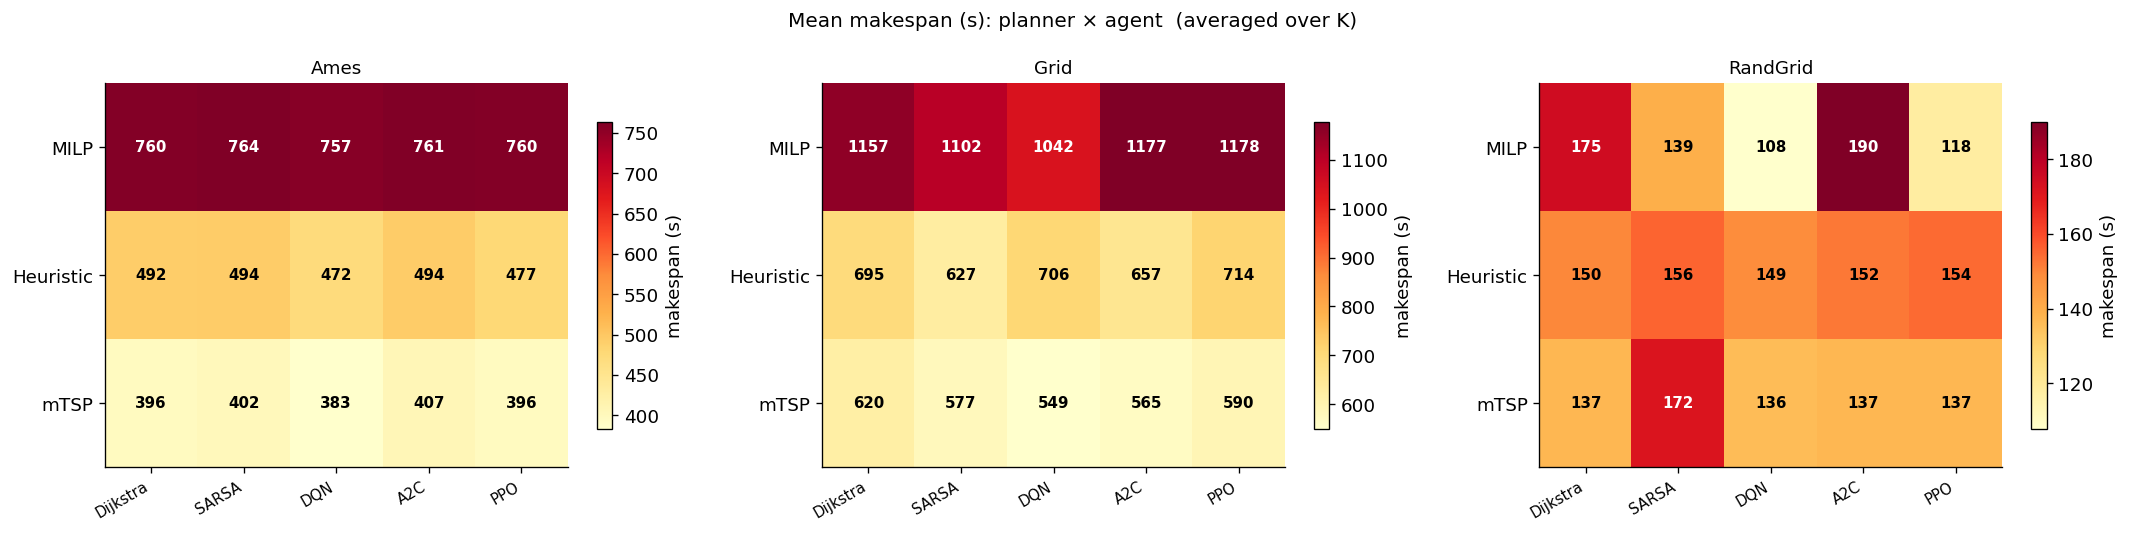

In [25]:
fig, axes = plt.subplots(1, len(NET_ORDER), figsize=(6 * len(NET_ORDER), 4.5), squeeze=False)
fig.suptitle('Mean makespan (s): planner × agent  (averaged over K)', fontsize=12)

agent_labels_ordered = [AGENT_LABELS[a] for a in AGENT_ORDER]

for ax, net in zip(axes[0], NET_ORDER):
    sub = df[df['network'] == net].groupby(['planner', 'agent'])['makespan_s'].mean().unstack('agent')
    sub = sub.reindex(index=PLANNER_ORDER, columns=AGENT_ORDER)

    vals = sub.values.astype(float)
    valid = vals[~np.isnan(vals)]
    vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

    im = ax.imshow(vals, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(AGENT_ORDER)))
    ax.set_xticklabels(agent_labels_ordered, rotation=30, ha='right', fontsize=9)
    ax.set_yticks(range(len(PLANNER_ORDER)))
    ax.set_yticklabels(PLANNER_ORDER)
    ax.set_title(net, fontsize=11)
    for i in range(len(PLANNER_ORDER)):
        for j in range(len(AGENT_ORDER)):
            v = vals[i, j]
            if not np.isnan(v):
                brightness = (v - vmin) / (vmax - vmin + 1e-9)
                ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=9,
                        color='white' if brightness > 0.6 else 'black', fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8, label='makespan (s)')

fig.tight_layout()
plt.show()

## Heatmap: throughput by planner × agent

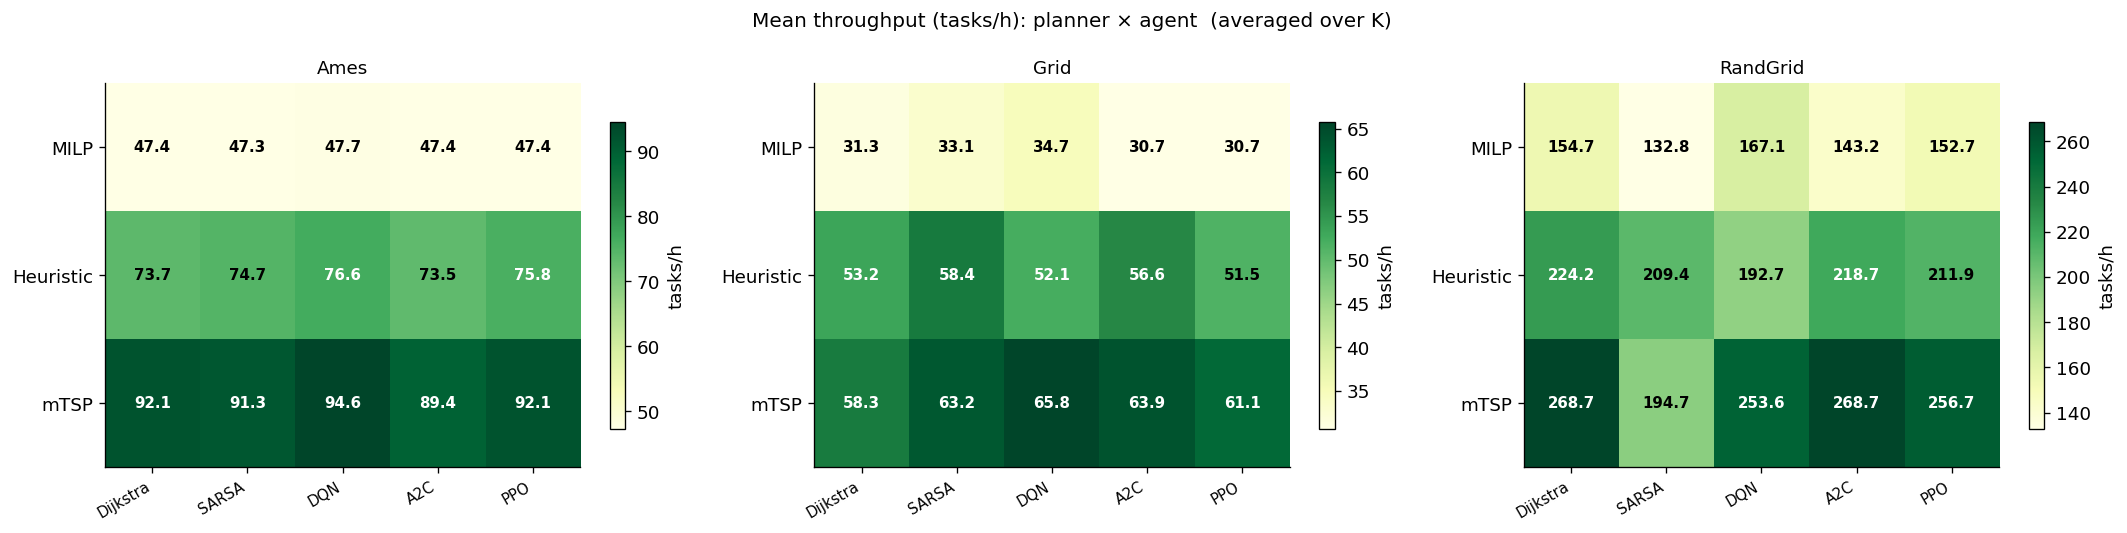

In [26]:
fig, axes = plt.subplots(1, len(NET_ORDER), figsize=(6 * len(NET_ORDER), 4.5), squeeze=False)
fig.suptitle('Mean throughput (tasks/h): planner × agent  (averaged over K)', fontsize=12)

for ax, net in zip(axes[0], NET_ORDER):
    sub = df[df['network'] == net].groupby(['planner', 'agent'])['throughput_tasks_per_h'].mean().unstack('agent')
    sub = sub.reindex(index=PLANNER_ORDER, columns=AGENT_ORDER)

    vals = sub.values.astype(float)
    valid = vals[~np.isnan(vals)]
    vmin, vmax = (valid.min(), valid.max()) if len(valid) else (0, 1)

    im = ax.imshow(vals, aspect='auto', cmap='YlGn', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(AGENT_ORDER)))
    ax.set_xticklabels(agent_labels_ordered, rotation=30, ha='right', fontsize=9)
    ax.set_yticks(range(len(PLANNER_ORDER)))
    ax.set_yticklabels(PLANNER_ORDER)
    ax.set_title(net, fontsize=11)
    for i in range(len(PLANNER_ORDER)):
        for j in range(len(AGENT_ORDER)):
            v = vals[i, j]
            if not np.isnan(v):
                brightness = (v - vmin) / (vmax - vmin + 1e-9)
                ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=9,
                        color='white' if brightness > 0.6 else 'black', fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8, label='tasks/h')

fig.tight_layout()
plt.show()

## Makespan vs. distance scatter

Color = agent, marker = planner, size ∝ K. Averaged over networks.

KeyError: 4

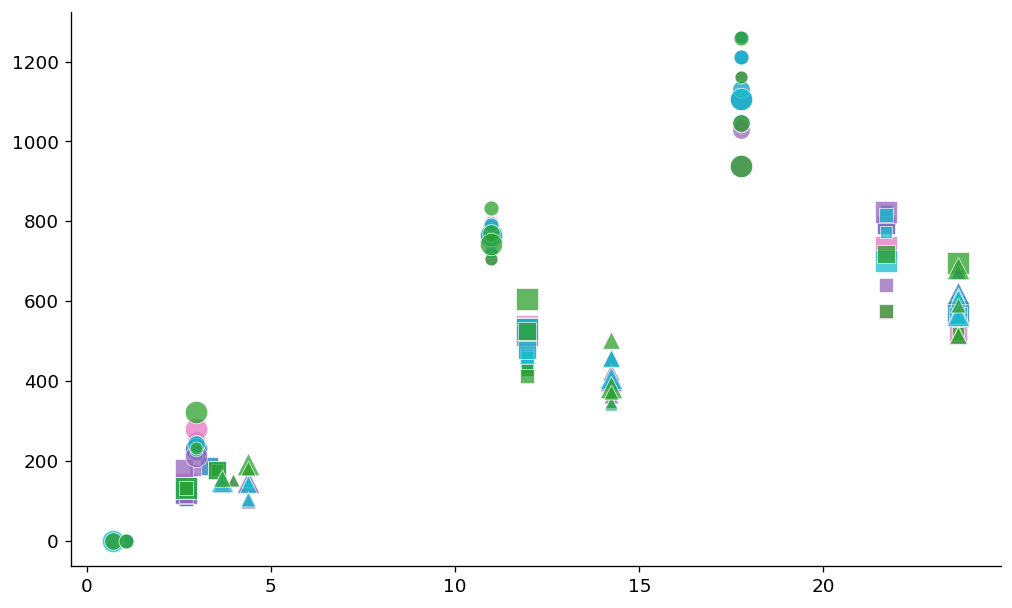

In [27]:
from matplotlib.lines import Line2D

PLANNER_MARKERS = {'MILP': 'o', 'Heuristic': 's', 'mTSP': '^'}
K_SIZES = {k: s for k, s in zip(K_VALUES, [60, 110, 180])}

fig, ax = plt.subplots(figsize=(10, 6))

seen_agents, seen_planners = set(), set()
for _, row in df.iterrows():
    a, pl, k = row['agent'], row['planner'], row['K']
    ax.scatter(
        row['total_distance_km'], row['makespan_s'],
        color=AGENT_COLORS[a],
        marker=PLANNER_MARKERS.get(pl, 'o'),
        s=K_SIZES.get(k, 80),
        alpha=0.75, edgecolors='white', linewidths=0.5,
    )
    seen_agents.add(a)
    seen_planners.add(pl)

agent_handles = [
    Line2D([0],[0], marker='o', color='w', markerfacecolor=AGENT_COLORS[a],
           markersize=9, label=AGENT_LABELS[a])
    for a in AGENT_ORDER if a in seen_agents
]
planner_handles = [
    Line2D([0],[0], marker=PLANNER_MARKERS[p], color='gray',
           linestyle='None', markersize=9, label=p)
    for p in PLANNER_ORDER if p in seen_planners
]
k_handles = [
    Line2D([0],[0], marker='o', color='gray', linestyle='None',
           markersize=np.sqrt(K_SIZES[k]), label=f'K={k}')
    for k in K_VALUES
]

leg1 = ax.legend(handles=agent_handles, title='Agent', frameon=False, fontsize=9,
                 loc='upper left', title_fontsize=9)
leg2 = ax.legend(handles=planner_handles, title='Planner', frameon=False, fontsize=9,
                 loc='upper center', title_fontsize=9)
leg3 = ax.legend(handles=k_handles, title='K', frameon=False, fontsize=9,
                 loc='upper right', title_fontsize=9)
ax.add_artist(leg1)
ax.add_artist(leg2)

ax.set_xlabel('Total distance (km)')
ax.set_ylabel('Makespan (s)')
ax.set_title('Makespan vs. distance  (color=agent, marker=planner, size∝K)')
fig.tight_layout()
plt.show()

## K effect per agent

How does each TRSP agent respond to increasing traffic slot granularity?
Averaged over planners and networks.

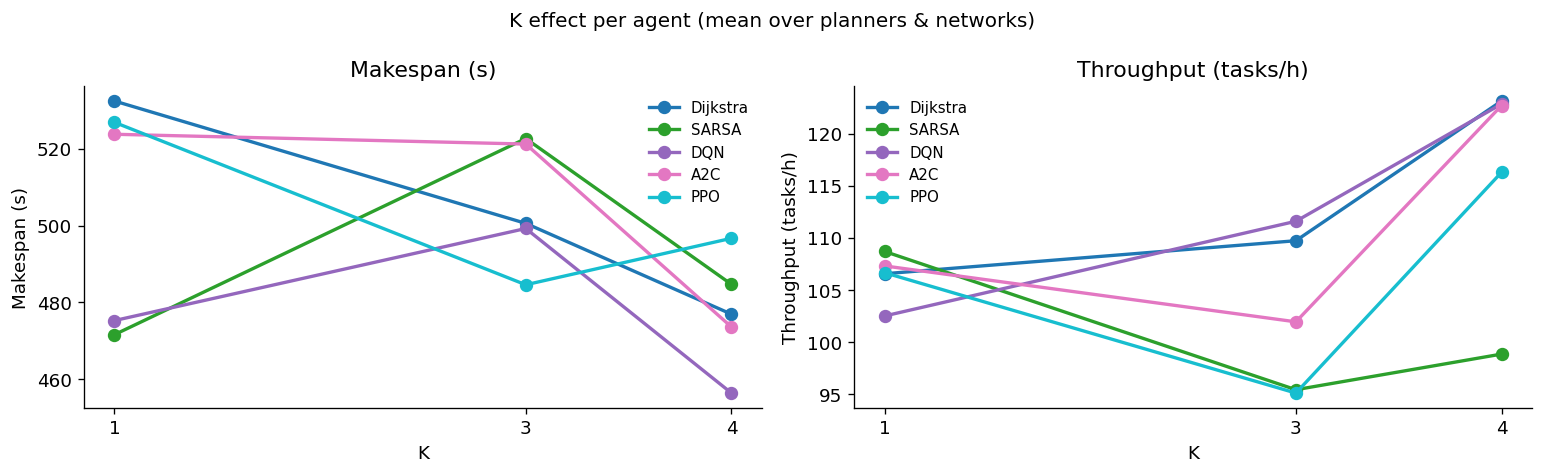

In [ ]:
if len(K_VALUES) < 2:
    print("Only one K value.")
else:
    agg_ka = df.groupby(['agent', 'K'])[['makespan_s', 'throughput_tasks_per_h']].mean().reset_index()

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle('K effect per agent (mean over planners & networks)', fontsize=12)

    for ax, (metric, ylabel) in zip(axes, [
        ('makespan_s',             'Makespan (s)'),
        ('throughput_tasks_per_h', 'Throughput (tasks/h)'),
    ]):
        for agent in AGENT_ORDER:
            sub = agg_ka[agg_ka['agent'] == agent].sort_values('K')
            ax.plot(
                sub['K'], sub[metric],
                color=AGENT_COLORS[agent],
                marker='o', linewidth=2, markersize=7,
                label=AGENT_LABELS[agent],
            )
        ax.set_xlabel('K')
        ax.set_ylabel(ylabel)
        ax.set_title(ylabel)
        ax.set_xticks(K_VALUES)
        ax.legend(frameon=False, fontsize=9)

    fig.tight_layout()
    plt.show()

## Raw data table

In [28]:
display_cols = ['planner', 'agent', 'network', 'K', 'makespan_s', 'total_distance_km',
                'total_recharges', 'customers_served', 'throughput_tasks_per_h',
                'avg_inter_customer_gap_s']
df[display_cols].sort_values(['planner', 'network', 'agent', 'K']).round(2).reset_index(drop=True)

,planner,agent,network,K,makespan_s,total_distance_km,total_recharges,customers_served,throughput_tasks_per_h,avg_inter_customer_gap_s
0,Heuristic,a2c,Ames,1,460.0,11.95,0.0,10.0,78.26,40.56
1,Heuristic,a2c,Ames,2,539.0,11.95,0.0,10.0,66.79,46.33
2,Heuristic,a2c,Ames,3,538.0,11.95,0.0,10.0,66.91,40.33
3,Heuristic,a2c,Ames,4,439.0,11.95,0.0,10.0,82.00,34.11
4,Heuristic,dijkstra,Ames,1,460.0,11.95,0.0,10.0,78.26,37.56
...,...,...,...,...,...,...,...,...,...,...
175,mTSP,ppo,RandGrid,4,105.0,4.37,0.0,10.0,342.86,10.67
176,mTSP,sarsa,RandGrid,1,152.0,3.98,0.0,9.0,213.16,10.88
177,mTSP,sarsa,RandGrid,2,157.0,3.66,0.0,8.0,183.44,10.43
178,mTSP,sarsa,RandGrid,3,194.0,4.37,0.0,10.0,185.57,8.78


---

## SVC Traffic — Dijkstra vs DSP vs DQN-SVC

Results from `results/ta_evrp_results_dqn_svc.csv`: 3 planners × 3 TRSP agents × 3 networks. Traffic scales: Grid=1.5, RandGrid=2.5, Ames=2.0.

Three inner-navigation agents under live SVC background traffic:
- **Dijkstra** — static shortest path (length-weighted), traffic-agnostic baseline.
- **DSP** — Dynamic Shortest Path: re-plans each leg once over live edge speeds (non-learning, traffic-aware).
- **DQN-SVC** — learned policy conditioned on neighbour speeds.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

SVC_CSV = Path('../results/ta_evrp_results_dqn_svc.csv')

svc_raw = pd.read_csv(SVC_CSV)
svc_raw = svc_raw[svc_raw['status'] == 'ok'].copy()

_NET_LABELS = {
    'grid_road':            'Grid',
    'rand_grid_road_final': 'RandGrid',
    'ames_campus_final':    'Ames',
}
svc_raw['network'] = svc_raw['network_net_path'].apply(lambda p: _NET_LABELS.get(Path(p).stem, Path(p).stem))
svc_raw['planner'] = svc_raw['evrp_planner'].map({'milp': 'MILP', 'heuristic': 'Heuristic', 'mtsp': 'mTSP'})
svc_raw['agent']   = svc_raw['trsp_agent']

svc_raw['throughput_tasks_per_h'] = svc_raw['customers_served'] / svc_raw['makespan_h'].replace(0, np.nan)

SVC_NET_ORDER     = [n for n in ['Grid', 'RandGrid', 'Ames'] if n in svc_raw['network'].unique()]
SVC_PLANNER_ORDER = [p for p in ['MILP', 'Heuristic', 'mTSP'] if p in svc_raw['planner'].unique()]
# Baseline first, then the two traffic-aware agents (non-learning DSP, then learned DQN-SVC)
SVC_AGENT_ORDER   = [a for a in ['dijkstra', 'dsp', 'dqn_svc'] if a in svc_raw['agent'].unique()]
SVC_AGENT_COLORS  = {'dijkstra': '#DD8452', 'dsp': '#55A868', 'dqn_svc': '#4C72B0'}
SVC_AGENT_LABELS  = {'dijkstra': 'Dijkstra', 'dsp': 'DSP', 'dqn_svc': 'DQN-SVC'}
# Traffic-aware agents compared against the Dijkstra baseline
SVC_RL_AGENTS     = [a for a in SVC_AGENT_ORDER if a != 'dijkstra']

print(f"Rows: {len(svc_raw)}  |  Planners: {SVC_PLANNER_ORDER}  |  Agents: {SVC_AGENT_ORDER}  |  Networks: {SVC_NET_ORDER}")

# Flag suspect rows (makespan=0 or customers_served < 10)
suspect = svc_raw[(svc_raw['makespan_s'] == 0) | (svc_raw['customers_served'] < 10)]
if not suspect.empty:
    print("\nSuspect rows (makespan=0 or customers<10):")
    display(suspect[['planner', 'agent', 'network', 'makespan_s', 'customers_served', 'total_recharges']])

svc_raw[['planner', 'agent', 'network', 'makespan_s', 'total_distance_km',
         'customers_served', 'throughput_tasks_per_h']].sort_values(['planner', 'agent', 'network'])

### Summary: planner × agent × network

In [39]:
svc_summary = (
    svc_raw.groupby(['planner', 'agent', 'network'])
    [['makespan_s', 'total_distance_km', 'total_recharges', 'customers_served', 'throughput_tasks_per_h']]
    .mean()
    .round(2)
)
svc_summary

makespan_s  total_distance_km  total_recharges  \
planner   agent    network                                                    
Heuristic dijkstra Ames           597.0              11.95              0.0   
                   Grid           432.0              23.66              0.0   
                   RandGrid       187.0               3.55              0.0   
          dqn_svc  Ames           609.0              11.95              0.0   
                   Grid           378.0              23.66              0.0   
                   RandGrid       297.0               3.55              0.0   
          dsp      Ames           634.0              11.95              0.0   
                   Grid           723.0              21.69              0.0   
                   RandGrid       187.0               3.55              0.0   
MILP      dijkstra Ames           939.0              10.98              1.0   
                   Grid           927.0              17.75              1.0   
                   RandGrid       300.0               2.96              3.0   
          dqn_svc  Ames           943.0              10.98              1.0   
                   Grid           888.0              17.75              1.0   
                   RandGrid       310.0               2.96              3.0   
          dsp      Ames           939.0              10.98              1.0   
                   Grid           927.0              17.75              1.0   
                   RandGrid       300.0               2.96              3.0   
mTSP      dijkstra Ames           458.0              14.22              0.0   
                   Grid           404.0              23.66              0.0   
                   RandGrid       254.0               4.37              0.0   
          dqn_svc  Ames           519.0              14.22              0.0   
                   Grid           435.0              23.66              0.0   
                   RandGrid       268.0               4.37              0.0   
          dsp      Ames           458.0              14.22              0.0   
                   Grid           404.0              23.66              0.0   
                   RandGrid       254.0               4.37              0.0   

                             customers_served  throughput_tasks_per_h  
planner   agent    network                                             
Heuristic dijkstra Ames                  10.0                   60.30  
                   Grid                  10.0                   83.33  
                   RandGrid              10.0                  192.51  
          dqn_svc  Ames                  10.0                   59.11  
                   Grid                  10.0                   95.24  
                   RandGrid              10.0                  121.21  
          dsp      Ames                  10.0                   56.78  
                   Grid                  10.0                   49.79  
                   RandGrid              10.0                  192.51  
MILP      dijkstra Ames                  10.0                   38.34  
                   Grid                  10.0                   38.83  
                   RandGrid              10.0                  120.00  
          dqn_svc  Ames                  10.0                   38.18  
                   Grid                  10.0                   40.54  
                   RandGrid              10.0                  116.13  
          dsp      Ames                  10.0                   38.34  
                   Grid                  10.0                   38.83  
                   RandGrid              10.0                  120.00  
mTSP      dijkstra Ames                  10.0                   78.60  
                   Grid                  10.0                   89.11  
                   RandGrid              10.0                  141.73  
          dqn_svc  Ames                  10.0                   69.36  
         

### Dijkstra vs DSP vs DQN-SVC — makespan and throughput by network

In [ ]:
# Agent comparison: grouped bars (agent) per network, faceted by metric, averaged over planners
svc_agg_agent = svc_raw.groupby(['agent', 'network'])[
    ['makespan_s', 'total_distance_km', 'throughput_tasks_per_h', 'customers_served']
].mean().reset_index()

svc_metrics_cfg = [
    ('makespan_s',             'Makespan (s)',         False),
    ('total_distance_km',      'Total distance (km)',  False),
    ('throughput_tasks_per_h', 'Throughput (tasks/h)', True),
    ('customers_served',       'Customers served',     True),
]

x       = np.arange(len(SVC_NET_ORDER))
width   = 0.8 / len(SVC_AGENT_ORDER)
offsets = np.linspace(-(len(SVC_AGENT_ORDER)-1)/2*width, (len(SVC_AGENT_ORDER)-1)/2*width, len(SVC_AGENT_ORDER))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
fig.suptitle('SVC traffic — Dijkstra vs DSP vs DQN-SVC (mean over planners)', fontsize=13)

for ax, (metric, ylabel, higher_better) in zip(axes.flat, svc_metrics_cfg):
    for offset, agent in zip(offsets, SVC_AGENT_ORDER):
        vals = [
            svc_agg_agent[(svc_agg_agent['agent'] == agent) & (svc_agg_agent['network'] == net)][metric].mean()
            for net in SVC_NET_ORDER
        ]
        ax.bar(x + offset, vals, width,
               color=SVC_AGENT_COLORS[agent], alpha=0.87,
               label=SVC_AGENT_LABELS[agent], edgecolor='white', linewidth=0.4)
    ax.set_xticks(x)
    ax.set_xticklabels(SVC_NET_ORDER)
    ax.set_xlabel('Network')
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel)
    ax.text(0.98, 0.97, '↑ better' if higher_better else '↓ better',
            transform=ax.transAxes, ha='right', va='top', fontsize=9, color='gray')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(SVC_AGENT_ORDER),
           bbox_to_anchor=(0.5, -0.03), frameon=False, fontsize=11)
fig.tight_layout()
plt.show()

### DSP and DQN-SVC % improvement over Dijkstra — per planner × network

Each traffic-aware agent (DSP, DQN-SVC) compared against the Dijkstra baseline for the same planner × network. Positive = better than Dijkstra (faster makespan / higher throughput).

In [ ]:
pn = svc_raw.groupby(['planner', 'agent', 'network'])[
    ['makespan_s', 'throughput_tasks_per_h']
].mean().reset_index()

# % change vs Dijkstra for each traffic-aware agent, per planner × network.
# makespan_pct: + = faster than Dijkstra;  throughput_pct: + = higher than Dijkstra.
labels = []
delta = {a: {'makespan_pct': [], 'throughput_pct': []} for a in SVC_RL_AGENTS}
for pl in SVC_PLANNER_ORDER:
    for net in SVC_NET_ORDER:
        base = pn[(pn['planner'] == pl) & (pn['agent'] == 'dijkstra') & (pn['network'] == net)]
        if base.empty:
            continue
        b_ms = base['makespan_s'].values[0]
        b_tp = base['throughput_tasks_per_h'].values[0]
        labels.append(f'{pl}\n{net}')
        for a in SVC_RL_AGENTS:
            rl = pn[(pn['planner'] == pl) & (pn['agent'] == a) & (pn['network'] == net)]
            if rl.empty:
                delta[a]['makespan_pct'].append(np.nan)
                delta[a]['throughput_pct'].append(np.nan)
                continue
            r_ms = rl['makespan_s'].values[0]
            r_tp = rl['throughput_tasks_per_h'].values[0]
            delta[a]['makespan_pct'].append(-(r_ms - b_ms) / max(abs(b_ms), 1e-9) * 100)   # + = faster
            delta[a]['throughput_pct'].append((r_tp - b_tp) / max(abs(b_tp), 1e-9) * 100)   # + = more

x       = np.arange(len(labels))
width   = 0.8 / max(len(SVC_RL_AGENTS), 1)
offsets = np.linspace(-(len(SVC_RL_AGENTS)-1)/2*width, (len(SVC_RL_AGENTS)-1)/2*width, len(SVC_RL_AGENTS))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
fig.suptitle('% change vs Dijkstra baseline  (+ = better)', fontsize=12)

for ax, (col, title) in zip(axes, [
    ('makespan_pct',   '% makespan reduction  (+ = faster)'),
    ('throughput_pct', '% throughput increase (+ = more)'),
]):
    for offset, a in zip(offsets, SVC_RL_AGENTS):
        ax.bar(x + offset, delta[a][col], width,
               color=SVC_AGENT_COLORS[a], alpha=0.85,
               label=SVC_AGENT_LABELS[a], edgecolor='white', linewidth=0.4)
    ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, fontsize=8.5, rotation=30, ha='right')
    ax.set_ylabel('%')
    ax.set_title(title, fontsize=10)

handles, lbls = axes[0].get_legend_handles_labels()
fig.legend(handles, lbls, loc='lower center', ncol=len(SVC_RL_AGENTS),
           bbox_to_anchor=(0.5, -0.06), frameon=False, fontsize=11)
fig.tight_layout()
plt.show()

### Heatmap: makespan by planner × network, per agent

In [ ]:
n_agents = len(SVC_AGENT_ORDER)
fig, axes = plt.subplots(1, n_agents, figsize=(5.5 * n_agents, 3.8))
if n_agents == 1:
    axes = [axes]
fig.suptitle('Makespan (s): planner × network  (lower = better)', fontsize=12)

# Shared colour scale across all agents for fair comparison
all_vals = svc_raw.groupby(['planner', 'agent', 'network'])['makespan_s'].mean()
valid_vals = all_vals[all_vals > 0].values
vmin, vmax = (valid_vals.min(), valid_vals.max()) if len(valid_vals) else (0, 1)

for ax, agent in zip(axes, SVC_AGENT_ORDER):
    pivot = (
        svc_raw[svc_raw['agent'] == agent]
        .groupby(['planner', 'network'])['makespan_s']
        .mean()
        .unstack('network')
        .reindex(index=SVC_PLANNER_ORDER, columns=SVC_NET_ORDER)
    )
    vals = pivot.values.astype(float)
    im = ax.imshow(vals, aspect='auto', cmap='YlOrRd', vmin=vmin, vmax=vmax)
    ax.set_xticks(range(len(SVC_NET_ORDER)))
    ax.set_xticklabels(SVC_NET_ORDER)
    ax.set_yticks(range(len(SVC_PLANNER_ORDER)))
    ax.set_yticklabels(SVC_PLANNER_ORDER)
    ax.set_title(SVC_AGENT_LABELS[agent], fontsize=11)
    for i in range(len(SVC_PLANNER_ORDER)):
        for j in range(len(SVC_NET_ORDER)):
            v = vals[i, j]
            if not np.isnan(v):
                brightness = (v - vmin) / (vmax - vmin + 1e-9)
                ax.text(j, i, f'{v:.0f}', ha='center', va='center', fontsize=10,
                        color='white' if brightness > 0.6 else 'black', fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.85, label='makespan (s)')

fig.tight_layout()
plt.show()

### Raw data

In [ ]:
svc_display = ['planner', 'agent', 'network', 'traffic_svc_traffic_scale',
               'makespan_s', 'total_distance_km', 'total_recharges',
               'customers_served', 'throughput_tasks_per_h', 'avg_inter_customer_gap_s']
svc_raw[svc_display].sort_values(['planner', 'agent', 'network']).round(2).reset_index(drop=True)